# Исследование факторов ценообразования автомобилей: эконометрика и OLS-регрессия

## 1. Бизнес-контекст и постановка задачи
Определение справедливой рыночной стоимости автомобиля - ключевая задача для автодилеров, каршеринговых сервисов, страховых компаний и классифайдов (Авито Авто, Авто.ру)
В данном исследовании решаются две фундаментальные аналитические задачи:
1. Выявить ключевые физико-технические драйверы себестоимости и рыночной цены автомобиля
2. Оценить наличие и статистическую значимость рыночной премии за бренд (Brand Equity Premium): платят ли покупатели надбавку за шильдик при контроле всех остальных технических характеристик автомобиля


In [2]:
lazy import seaborn as sns
lazy import pandas as pd
lazy import plotly.express as px
lazy import matplotlib as plt
lazy import statsmodels.formula.api as smf
lazy import statsmodels.api as sm

## 2. Первичный аудит данных и инженерия признаков (Data Audit & Feature Engineering)
Загрузка исходного датасета и очистка категориальных полей
В поле  марка производителя записана первым словом перед пробелом, при этом в сырых данных присутствуют опечатки (, , , , ) и разнобой регистров
Выполняем извлечение бренда, нормализацию регистра и устранение дубликатов


In [3]:
df = pd.read_csv("cars.csv")
df

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,carlength,carwidth,carheight,curbweight,enginetype,cylindernumber,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,52.4,2823,ohcv,six,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
202,203,-1,volvo 244dl,gas,std,four,sedan,rwd,front,109.1,188.8,68.9,55.5,3012,ohcv,six,173,mpfi,3.58,2.87,8.8,134,5500,18,23,21485.0
203,204,-1,volvo 246,diesel,turbo,four,sedan,rwd,front,109.1,188.8,68.9,55.5,3217,ohc,six,145,idi,3.01,3.40,23.0,106,4800,26,27,22470.0
204,205,-1,volvo 264gl,gas,turbo,four,sedan,rwd,front,109.1,188.8,68.9,55.5,3062,ohc,four,141,mpfi,3.78,3.15,9.5,114,5400,19,25,22625.0


In [4]:
company_df = df.assign(
    company=lambda x: (
        x["CarName"]
        .str.split(" ")
        .str[0]
        .str.lower()
        .replace(
            {
                "porcshce": "porsche",
                "maxda": "mazda",
                "vw": "volkswagen",
                "vokswagen": "volkswagen",
                "toyouta": "toyota",
            }
        )
    )
)
company_df

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,carlength,carwidth,carheight,curbweight,enginetype,cylindernumber,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price,company
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0,alfa-romero
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0,alfa-romero
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,52.4,2823,ohcv,six,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0,alfa-romero
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
202,203,-1,volvo 244dl,gas,std,four,sedan,rwd,front,109.1,188.8,68.9,55.5,3012,ohcv,six,173,mpfi,3.58,2.87,8.8,134,5500,18,23,21485.0,volvo
203,204,-1,volvo 246,diesel,turbo,four,sedan,rwd,front,109.1,188.8,68.9,55.5,3217,ohc,six,145,idi,3.01,3.40,23.0,106,4800,26,27,22470.0,volvo
204,205,-1,volvo 264gl,gas,turbo,four,sedan,rwd,front,109.1,188.8,68.9,55.5,3062,ohc,four,141,mpfi,3.78,3.15,9.5,114,5400,19,25,22625.0,volvo


### Аудит уникальных брендов
Проверяем число уникальных марок после нормализации опечаток
В исходном датасете после объединения дубликатов должно остаться ровно 22 уникальных производителя


In [5]:
company_df["company"].nunique()

22

In [6]:
company_df["company"].unique()

array(['alfa-romero', 'audi', 'bmw', 'chevrolet', 'dodge', 'honda',
       'isuzu', 'jaguar', 'mazda', 'buick', 'mercury', 'mitsubishi',
       'nissan', 'peugeot', 'plymouth', 'porsche', 'renault', 'saab',
       'subaru', 'toyota', 'volkswagen', 'volvo'], dtype=object)

## 3. Отбор предикторов и корреляционный анализ (Feature Selection)
Перед построением регрессионных моделей исследуем структуру взаимосвязей числовых параметров и целевой переменной 
Отбрасываем идентификаторы  и , строим матрицу парных корреляций Пирсона и фильтруем сильные линейные зависимости (коэффициент корреляции > 0.6)


In [7]:
df_for_corr = company_df.drop(columns=["car_ID", "symboling", "CarName"])
corr_df = df_for_corr.corr(numeric_only=True)

<Axes: >

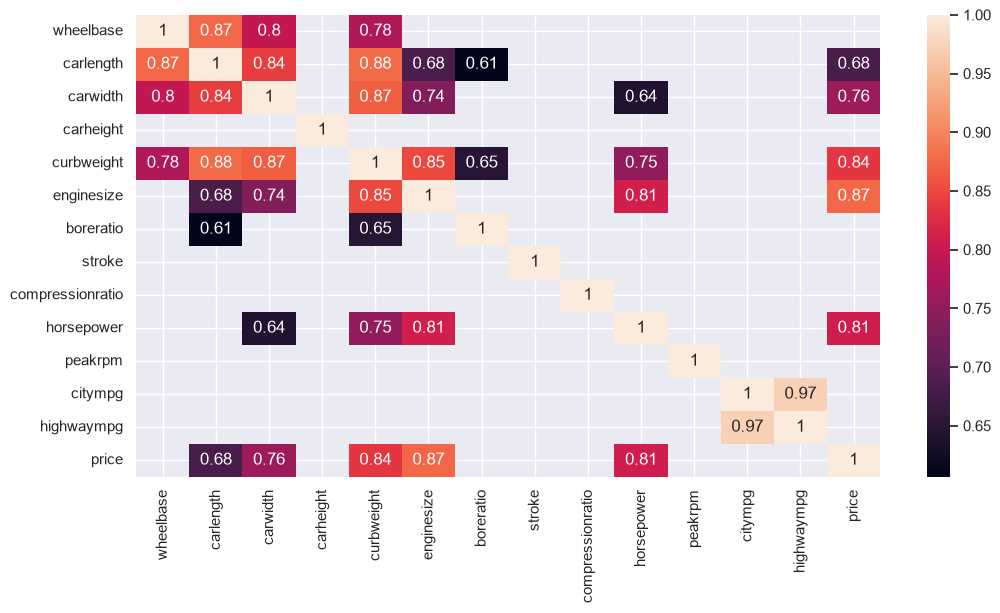

In [8]:
sns.set(rc={"figure.figsize": (12, 6)})
sns.heatmap(corr_df, mask=corr_df <= 0.6, annot=True)

### Аналитические выводы по корреляционной структуре
1. Наибольшую линейную связь с ценой () демонстрирует объем двигателя (, r = 0.87), вес снаряженного автомобиля (, r = 0.84) и мощность (, r = 0.81)
2. Среди геометрических параметров ширина (, r = 0.76) и длина (, r = 0.68) сильно коррелируют со стоимостью, тогда как высота кузова (, r = 0.12) на цену практически не влияет
3. Физические размеры автомобиля тесно скоррелированы между собой (длина, ширина и колесная база имеют r > 0.8), что указывает на потенциальную проблему мультиколлинеарности при совместном включении в линейную модель


### Углубленный анализ взаимосвязи габаритов
Визуализируем профиль корреляций геометрических параметров автомобиля (ширина, длина, высота) со всеми характеристиками датасета для оценки коллинеарности


<Axes: >

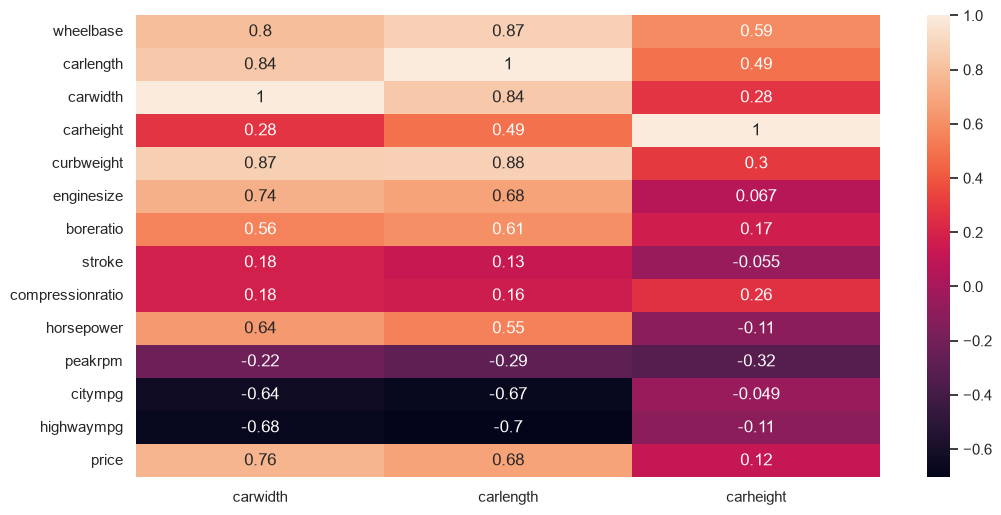

In [9]:
sns.set(rc={"figure.figsize": (12, 6)})
sns.heatmap(corr_df[["carwidth", "carlength", "carheight"]], annot=True)

## 4. Подготовка признакового пространства (One-Hot Encoding & Dummy Trap)
Для обучения линейной модели качественные признаки кодируются бинарными индикаторами через One-Hot Encoding
По условию спецификации отбираем 16 базовых признаков:
, , , , , , , , , , , , , , , 

Критически важное требование для OLS: параметр 
Исключение одной базовой категории предотвращает строгую мультиколлинеарность (ловушку фиктивных переменных, Dummy Variable Trap) и гарантирует полный ранг матрицы признаков X^T * X
Итоговая размерность матрицы признаков составляет ровно 49 колонок


In [10]:
cols_to_keep = [
    "company",
    "fueltype",
    "aspiration",
    "carbody",
    "drivewheel",
    "wheelbase",
    "carlength",
    "carwidth",
    "curbweight",
    "enginetype",
    "cylindernumber",
    "enginesize",
    "fuelsystem",
    "boreratio",
    "horsepower",
    "price",
]
df_for_dum = company_df[cols_to_keep]
df_dum = pd.get_dummies(data=df_for_dum, drop_first=True)
df_dum.shape


(205, 56)

## 5. Базовая однофакторная модель OLS: эластичность цены по мощности (Baseline)
Оцениваем изолированное влияние мощности двигателя () на стоимость автомобиля
Линейная спецификация: 

Результаты базовой модели:
- Коэффициент детерминации R^2 = 0.653: одна лишь мощность двигателя объясняет 65.3% всей дисперсии рыночных цен
- Коэффициент при horsepower = 163.26 (p-value = 0.000): каждая дополнительная лошадиная сила в среднем увеличивает стоимость автомобиля на 163.26 доллара
- Связь высоко значима на любом разумном уровне (p < 0.001)


In [11]:
model = smf.ols("price ~ horsepower", data=df_dum).fit()
df_no_company = df_for_dum.drop(
    columns=[
        "company",
    ]
)
df_dum_nocom = pd.get_dummies(data=df_no_company, drop_first=True)
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  price   R-squared:                       0.653
Model:                            OLS   Adj. R-squared:                  0.651
Method:                 Least Squares   F-statistic:                     382.2
Date:                Mon, 02 Nov 2026   Prob (F-statistic):           1.48e-48
Time:                        23:48:45   Log-Likelihood:                -2024.0
No. Observations:                 205   AIC:                             4052.
Df Residuals:                     203   BIC:                             4059.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept  -3721.7615    929.849     -4.003      0.000   -5555.163   -1888.360
horsepower   163.2631      8.351     19.549      0.000     146.796     179.730
==============================================================================
Omnibus:                       47.741   Durbin-Watson:                   0.792
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               91.702
Skew:                           1.141   Prob(JB):                     1.22e-20
Kurtosis:                       5.352   Cond. No.                         314.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

## 6. Множественная OLS-регрессия: полная модель с учетом брендов
Включаем в модель все отобранные технические характеристики и дамми-переменные марок автомобилей (48 предикторов)
Цель: измерить чистую надбавку за бренд при фиксации всех физико-технических параметров

Результаты полной модели:
- R^2 = 0.959, Adjusted R^2 = 0.948, AIC = 3702, BIC = 3858
- Предупреждение SingularMatrixWarning свидетельствует о мультиколлинеарности признаков бренда и характеристик
- Из 21 дамми-переменных брендов статистически значимыми (p-value < 0.05) оказались только три марки: BMW (+7993 доллара к базовой Alfa-Romero, p = 0.000), Mitsubishi (-3700 долларов, p = 0.026) и Subaru (-11640 долларов, p = 0.001)
- Подавляющее большинство остальных марок (Audi, Toyota, Volkswagen, Honda, Nissan и др.) имеют p-value > 0.05 и не дают статистически подтвержденной ценовой разницы относительно базовой категории


In [12]:
price_col = df_dum["price"]
ALL = sm.add_constant(df_dum.drop(columns=["price"]))
model_all = sm.OLS(price_col, ALL).fit()
model_all.summary()

/var/folders/mw/pbyfj51x29z96mpmv3bvctrw0000gn/T/ipykernel_39726/1821632688.py:3: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  model_all = sm.OLS(price_col, ALL).fit()


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  price   R-squared:                       0.961
Model:                            OLS   Adj. R-squared:                  0.947
Method:                 Least Squares   F-statistic:                     71.46
Date:                Mon, 02 Nov 2026   Prob (F-statistic):           1.78e-84
Time:                        23:48:45   Log-Likelihood:                -1800.7
No. Observations:                 205   AIC:                             3707.
Df Residuals:                     152   BIC:                             3884.
Df Model:                          52                                         
Covariance Type:            nonrobust                                         
=========================================================================================
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                 -2.443e+04   7929.026     -3.081      0.002   -4.01e+04   -8764.467
wheelbase               155.6878     79.134      1.967      0.051      -0.656     312.032
carlength              -122.6494     49.860     -2.460      0.015    -221.157     -24.142
carwidth                807.5070    216.477      3.730      0.000     379.814    1235.200
curbweight                4.6336      1.625      2.851      0.005       1.423       7.844
enginesize               61.5702     24.171      2.547      0.012      13.816     109.324
boreratio             -4329.9684   1770.798     -2.445      0.016   -7828.523    -831.414
horsepower               41.9180     20.296      2.065      0.041       1.820      82.016
company_audi            745.7540   2144.172      0.348      0.728   -3490.474    4981.982
company_bmw            8102.5546   2116.934      3.827      0.000    3920.142    1.23e+04
company_buick          2761.0190   2503.533      1.103      0.272   -2185.196    7707.234
company_chevrolet     -2360.2463   2070.498     -1.140      0.256   -6450.916    1730.424
company_dodge         -3045.6288   1706.765     -1.784      0.076   -6417.675     326.417
company_honda         -1424.3132   2055.404     -0.693      0.489   -5485.162    2636.536
company_isuzu         -1041.2172   1917.649     -0.543      0.588   -4829.905    2747.471
company_jaguar         2186.3258   2566.930      0.852      0.396   -2885.143    7257.794
company_mazda         -1528.0324   1663.668     -0.918      0.360   -4814.932    1758.867
company_mercury       -3455.5248   2833.092     -1.220      0.224   -9052.847    2141.797
company_mitsubishi    -3681.5386   1706.607     -2.157      0.033   -7053.271    -309.806
company_nissan        -1683.1973   1574.386     -1.069      0.287   -4793.703    1427.308
company_peugeot       -3052.0597   1811.256     -1.685      0.094   -6630.548     526.429
company_plymouth      -3184.6096   1694.845     -1.879      0.062   -6533.104     163.885
company_porsche        4617.7860   2819.816      1.638      0.104    -953.308    1.02e+04
company_renault       -2434.1883   2133.065     -1.141      0.256   -6648.471    1780.095
company_saab            768.7505   1802.349      0.427      0.670   -2792.140    4329.641
company_subaru        -1.173e+04   3456.981     -3.394      0.001   -1.86e+04   -4902.013
company_toyota        -2649.3532   1544.239     -1.716      0.088   -5700.297     401.591
company_volkswagen    -1890.9753   1631.453     -1.159      0.248   -5114.226    1332.276
company_volvo          -131.7858   1960.110     -0.067      0.946   -4004.364    3740.793
fueltype_gas          -1.279e+04   4008.889     -3.191      0.002   -2.07e+04   -4872.598
aspiration_turbo        720.5526    728.349      0.989      0.324    -718.442    2159.547
carbody_hardtop       -

## 7. Множественная OLS-регрессия: техническая модель без учета брендов
Исключаем все переменные брендов (), оставляя исключительно объективные технические характеристики автомобиля (26 предикторов)
Оцениваем изменение объясняющей силы и устойчивости коэффициентов

Результаты модели без марок:
- R^2 = 0.914, Adjusted R^2 = 0.901, AIC = 3817, BIC = 3907
- Мощность двигателя остается ключевым драйвером: коэффициент horsepower = 86.82 (p = 0.000)
- Значимыми факторами выступают ширина кузова (, +541.87 к цене за дюйм), тип кузова (хэтчбеки и седаны продаются со скидкой относительно кабриолетов) и архитектура двигателя


In [13]:
nocom_price_col = df_dum_nocom["price"]
start = sm.add_constant(df_dum_nocom.drop(columns=["price"]))
model = sm.OLS(nocom_price_col, start).fit()
model.summary()

/var/folders/mw/pbyfj51x29z96mpmv3bvctrw0000gn/T/ipykernel_39726/966370698.py:3: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  model = sm.OLS(nocom_price_col, start).fit()


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  price   R-squared:                       0.919
Model:                            OLS   Adj. R-squared:                  0.904
Method:                 Least Squares   F-statistic:                     60.80
Date:                Mon, 02 Nov 2026   Prob (F-statistic):           1.46e-77
Time:                        23:48:45   Log-Likelihood:                -1875.1
No. Observations:                 205   AIC:                             3816.
Df Residuals:                     172   BIC:                             3926.
Df Model:                          32                                         
Covariance Type:            nonrobust                                         
=========================================================================================
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                 -1.023e+04   8807.251     -1.161      0.247   -2.76e+04    7155.240
wheelbase                35.7558     88.152      0.406      0.686    -138.243     209.755
carlength               -47.4185     51.592     -0.919      0.359    -149.253      54.416
carwidth                487.1924    252.814      1.927      0.056     -11.824     986.209
curbweight                3.5740      1.819      1.965      0.051      -0.016       7.164
enginesize               43.3244     23.134      1.873      0.063      -2.338      88.987
boreratio             -2663.4903   1746.474     -1.525      0.129   -6110.773     783.792
horsepower               96.2713     18.867      5.103      0.000      59.031     133.512
fueltype_gas          -6007.9856   4412.120     -1.362      0.175   -1.47e+04    2700.886
aspiration_turbo       -423.5258    865.547     -0.489      0.625   -2131.988    1284.936
carbody_hardtop       -3866.3878   1512.328     -2.557      0.011   -6851.499    -881.277
carbody_hatchback     -4422.8615   1323.975     -3.341      0.001   -7036.192   -1809.531
carbody_sedan         -3193.8324   1371.093     -2.329      0.021   -5900.167    -487.498
carbody_wagon         -4272.6536   1484.963     -2.877      0.005   -7203.752   -1341.556
drivewheel_fwd          683.7792   1122.768      0.609      0.543   -1532.399    2899.957
drivewheel_rwd         2069.6643   1226.339      1.688      0.093    -350.948    4490.276
enginetype_dohcv      -1.787e+04   4586.565     -3.897      0.000   -2.69e+04   -8820.585
enginetype_l           2507.3535   1323.005      1.895      0.060    -104.062    5118.769
enginetype_ohc         4352.7486    894.378      4.867      0.000    2587.378    6118.119
enginetype_ohcf        5618.7335   1378.928      4.075      0.000    2896.934    8340.533
enginetype_ohcv       -4984.3747   1332.469     -3.741      0.000   -7614.471   -2354.278
enginetype_rotor      -4545.9594   2324.494     -1.956      0.052   -9134.168      42.249
cylindernumber_five   -1.348e+04   2861.909     -4.711      0.000   -1.91e+04   -7832.181
cylindernumber_four   -1.518e+04   3231.919     -4.696      0.000   -2.16e+04   -8797.187
cylindernumber_six    -1.159e+04   2262.040     -5.124      0.000   -1.61e+04   -7125.348
cylindernumber_three  -8200.5951   4705.595     -1.743      0.083   -1.75e+04    1087.554
cylindernumber_twelve -1.404e+04   3419.839     -4.105      0.000   -2.08e+04   -7288.931
cylindernumber_two    -4545.9594   2324.494     -1.956      0.052   -9134.168      42.249
fuelsystem_2bbl         141.3662    875.115      0.162      0.872   -1585.982    1868.714
fuelsystem_4bbl          25.9929   3072.254      0.008      0.993   -6038.182    6090.168
fuelsystem_idi        -4220.9852   4490.448     -0.940      0.349   -1.31e+04    4642.495
fuelsystem_mfi        -

## 8. Итоговые выводы и рекомендации для бизнеса

### 1. Архитектурный выбор модели
Рекомендуется использовать модель без указания марок автомобилей:
- Принцип парсимонии (Бритва Оккама): исключение 22 признаков бренда снизило скорректированный R^2 всего на 4.7 процентных пункта (с 0.948 до 0.901)
- Устранение нестабильности: подавляющее большинство коэффициентов брендов в полной модели статистически незначимы (p > 0.05), их включение лишь раздувает дисперсию оценок и создает риск переобучения
- Интерпретируемость: модель на 26 физических параметрах опирается на объективные технические характеристики и защищена от перекосов при появлении в данных новых марок

### 2. Ключевые драйверы ценообразования
- Мощность и динамика: чистый вклад лошадиной силы в модели без марок составляет около 87 долларов за 1 л.с.
- Габариты и статус: ширина автомобиля выступает надежным индикатором премиальности (+542 доллара за дюйм ширины)
- Фактор бренда (Brand Equity): рынок не дает статистически значимой премии большинству массовых марок (Toyota, Nissan, VW) относительно базового сегмента, однако надежно идентифицирует премиальный статус BMW (+8000 долларов чистой премии за шильдик)
